# L1 (Partial Differential Equation Models in Engineering)
## Generation of Visual Artworks Inspired by Mathematical Physics Models

The formation mechanism of biological pigment patterns (such as leopard spots and rosettes) on animal skin is investigated using a two-morphogen Turing reaction-diffusion model. According to phylogenetic studies, the initial coat pattern of juveniles consists of small spots, which transform into more complex structures (rosettes or rings) as they grow and model parameters change [1]. How can a mathematical reaction-diffusion system imitate this biological process and generate aesthetically appealing generative art works?

Let morphogens $u$ and $v$ interact with each other and diffuse in space applying nonlinear quadratic and cubic laws, subject to zero-flux boundary conditions in the boundary regions.

## Overview
- This work examines the Turing reaction-diffusion mathematical model, described by a system of two coupled partial differential equations, which imitates biological morphogenesis and animal coat pigmentation.
- The solution methods include discretizing the domain, applying a central finite difference scheme to replace time and spatial derivatives, constructing a recursive algorithm, and performing numerical integration in a Python environment by altering model parameters across multiple growth stages.
### Research Objectives
To answer the raised research question, the following objectives are formulated:
1. Program a numerical solution of the reaction-diffusion equation system in a Python environment based on the two-stage Turing model described by Liu et al. (2006).
2. Investigate the impact of model parameters (scale $\delta$ and nonlinear interaction coefficients $r_2, r_3$) on pattern transformation by altering them during the simulation.
3. Apply 3D relief mapping and color palettes to generate aesthetically appealing artworks.
4. Perform visual validation of the model results by comparing them with the natural developmental stages of animal coat patterns (leopards).

## 1. Definitions

The study uses a two-morphogen Turing reaction-diffusion model [1], described by a system of partial differential equations:
$$
\begin{cases}
\frac{\partial u}{\partial t} = D \delta \nabla^2 u + \alpha u + v - r_2 u v - r_3 u v^2 \\
\frac{\partial v}{\partial t} = \delta \nabla^2 v + \beta v + \alpha u + r_2 u v + r_3 u v^2
\end{cases}
$$

- $u(x,y,t)$ – concentration of the first morphogen (activator) in space $(x,y)$ and time $t$.
- $v(x,y,t)$ – concentration of the second morphogen (inhibitor) in space $(x,y)$ and time $t$.
- $\nabla^2$ – Laplace operator, defining the dispersion (diffusion) of substances.
- $D$ – ratio of the diffusion coefficients of the activator and inhibitor.
- $\delta$ – relative diffusion strength variable.
- $\alpha, \beta$ – linear reaction coefficients responsible for the production and degradation of morphogens.
- $r_2, r_3$ – nonlinear quadratic and cubic interaction coefficients determining the formation of structures (spots, rings, rosettes).
- $\Delta t$ – time step; $\Delta x, \Delta y$ – spatial grid steps.

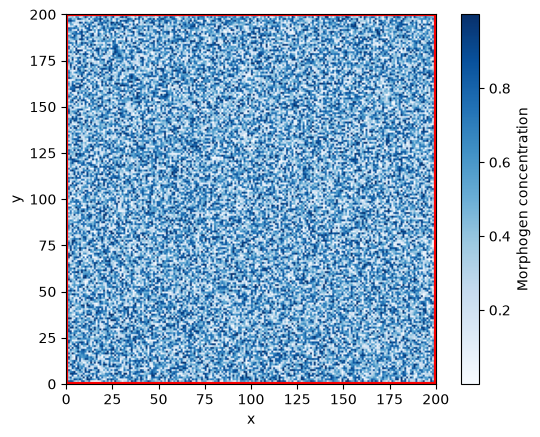

In [2]:
import numpy as np
import matplotlib.pyplot as plt

L = 200
noise = np.random.rand(L, L)
plt.imshow(noise, cmap='Blues', extent=[0, L, 0, L], origin='lower')
plt.colorbar(label='Morphogen concentration')
plt.plot([0, L, L, 0, 0], [0, 0, L, L, 0], color='red', linewidth=3)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

## 3. Modeling

**1. Spatial and Temporal Discretization**
The model space is divided into a rectangular grid with spatial steps $\Delta x$ and $\Delta y$, where we assume that $\Delta x = \Delta y = h$. Time is divided into discrete steps $\Delta t$.
The concentrations of morphogens at a point $(x, y)$ at time $t$ are denoted by indices: $u(x,y,t) \approx u_{i,j}^n$ and $v(x,y,t) \approx v_{i,j}^n$.

**2. Approximation of Spatial Derivatives**
Based on the central finite difference scheme, the second-order spatial derivatives can be analytically derived using a Taylor series expansion. According to the general definition of Taylor's theorem, any continuous function $f(x)$ around a point $x$ with a small change $\Delta x$ can be expressed as an infinite sum of derivatives:

$$f(x + \Delta x) = f(x) + \Delta x \cdot f'(x) + \frac{(\Delta x)^2}{2!} f''(x) + \frac{(\Delta x)^3}{3!} f'''(x) + \dots$$

When deriving the formula for the $x$-axis, time $n$ and the $y$-axis (index $j$) are treated as fixed constants, and only the spatial step $\Delta x = h$ varies.

The Taylor series expansion for the forward point ($x + h$, i.e., index $i + 1$) is written as:

$$u_{i+1} = u_i + h\frac{\partial u}{\partial x} + \frac{h^2}{2}\frac{\partial^2 u}{\partial x^2} + \frac{h^3}{6}\frac{\partial^3 u}{\partial x^3} + \dots$$

Then, the Taylor series expansion for the backward point ($x - h$, i.e., index $i - 1$) is written as:

$$u_{i-1} = u_i - h\frac{\partial u}{\partial x} + \frac{h^2}{2}\frac{\partial^2 u}{\partial x^2} - \frac{h^3}{6}\frac{\partial^3 u}{\partial x^3} + \dots$$

By adding both equations, it can be seen that the terms with the first derivative ($h \frac{\partial u}{\partial x}$) and other odd derivatives have opposite signs, and therefore they cancel each other out:
$$u_{i+1} + u_{i-1} = 2u_i + h^2 \frac{\partial^2 u}{\partial x^2} + O(h^4)$$

From this equation, the sought second derivative is expressed:
$$h^2 \frac{\partial^2 u}{\partial x^2} \approx u_{i+1} - 2u_i + u_{i-1}$$
$$\frac{\partial^2 u}{\partial x^2} \approx \frac{u_{i+1} - 2u_i + u_{i-1}}{h^2}$$

Introducing the full 2D spatial ($i, j$) and temporal ($n$) indices, this $x$-axis formula takes the following form:
$$\frac{\partial^2 u}{\partial x^2} \approx \frac{u_{i+1,j}^n - 2u_{i,j}^n + u_{i-1,j}^n}{h^2}$$

Similarly, by fixing the horizontal position and applying the same derivation to the $y$-axis (index $j$), we obtain:
$$\frac{\partial^2 u}{\partial y^2} \approx \frac{u_{i,j+1}^n - 2u_{i,j}^n + u_{i,j-1}^n}{h^2}$$

Adding both of these spatial derivatives forms the discrete two-dimensional Laplace operator $\nabla^2 u$, used in subsequent modeling calculations:
$$\nabla^2 u \approx \frac{u_{i+1,j}^n + u_{i-1,j}^n + u_{i,j+1}^n + u_{i,j-1}^n - 4u_{i,j}^n}{h^2}$$

**3. Approximation of the Time Derivative**
To model the system dynamics over time, the explicit forward Euler scheme is applied. This scheme originates from the definition of the derivative without evaluating the limit. In general form, when the time step is denoted by the index $i$, the iterative equation is written as follows:
$$u_{i+1} = u_i + \Delta t \cdot u'_i$$

Here, $u'_i$ is the time derivative of the function. Applying this principle to a two-dimensional reaction-diffusion system, the time index is moved to the top ($n$ and $n+1$), while the spatial position is denoted by subscripts ($i, j$). 

Replacing $u'_i$ with the partial time derivative $\frac{\partial u}{\partial t}$ yields the following relationship:
$$u_{i,j}^{n+1} = u_{i,j}^n + \Delta t \frac{\partial u}{\partial t}$$

Expressing this derivative gives a formula that allows the algorithm to iteratively compute the system state one step $\Delta t$ forward:
$$\frac{\partial u}{\partial t} \approx \frac{u_{i,j}^{n+1} - u_{i,j}^n}{\Delta t}$$

**4. Final Numerical Model Equations**
By substituting the discretized spatial and temporal derivatives into the original reaction-diffusion equations

In [3]:
import numpy as np

def calculate_new_values(U, V, dt, h, D, delta, alpha, beta, r2, r3):
    
    U_ij = U[1:-1, 1:-1]  # central
    U_ip1j = U[1:-1, 2:]  # right
    U_im1j = U[1:-1, :-2] # left
    U_ijp1 = U[2:, 1:-1]  # bottom
    U_ijm1 = U[:-2, 1:-1] # top

    V_ij = V[1:-1, 1:-1]
    V_ip1j = V[1:-1, 2:]
    V_im1j = V[1:-1, :-2]
    V_ijp1 = V[2:, 1:-1]
    V_ijm1 = V[:-2, 1:-1]

    laplace_U = (U_ip1j + U_im1j + U_ijp1 + U_ijm1 - 4 * U_ij) / h**2
    laplace_V = (V_ip1j + V_im1j + V_ijp1 + V_ijm1 - 4 * V_ij) / h**2

    gamma = -alpha # ensures that in the absence of diffusion, the system has a unique equilibrium point (0, 0). This allows variables u and v to be treated as concentration deviations from this zero resting state, rather than absolute quantities. 

    U_new = U_ij + dt * (D * delta * laplace_U + alpha * U_ij + V_ij - r2 * U_ij * V_ij - alpha * r3 * U_ij * (V_ij**2))
    V_new = V_ij + dt * (delta * laplace_V + gamma * U_ij + beta * V_ij + r2 * U_ij * V_ij + alpha * r3 * U_ij * (V_ij**2))

    return U_new, V_new

## 4. Simulation **Stage 1: Formation of juvenile leopard spots**

In this stage, the initial coat pattern of the juvenile is simulated – solid, fully filled spots. The process starts with random noise, which imitates natural variations in the skin. All parameters are taken from the paper by Liu et al. (2006) and correspond to the early developmental stage of the animal:

- **$\delta$ (delta = 6.0):** Reflects the surface area of the skin. A relatively large value corresponds to the still small body of the juvenile, thus forming large pattern outlines.
- **$D$ (0.45):** The difference in diffusion rates of substances (pigment activators and inhibitors) in the tissues. This value maintains a stable and round shape of the spots.
- **$r_2$ (2.0):** Control of pigment production at the center of the spot. A low value means that the center is stable, so the spots remain fully filled and do not turn into hollow rings.
- **$\alpha$, $\beta$, $r_3$:** The main system settings ensuring that specifically a spotted (leopard), rather than a striped (tiger or zebra), coat is generated.

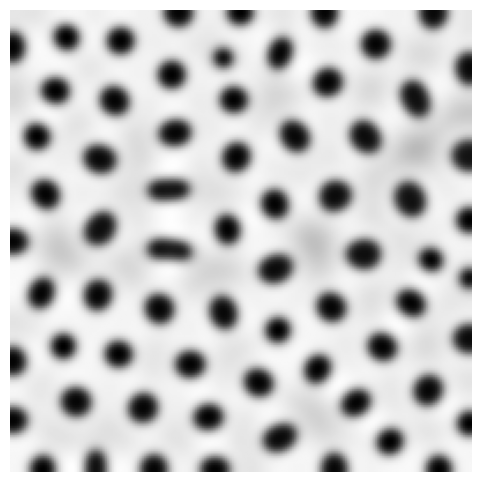

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters according to Liu et al. (2006)
D = 0.45
delta = 6.0
alpha = 0.899
beta = -0.91
r2 = 2.0
r3 = 3.5

nx, ny = 200, 200 # Spatial grid 
nt = 20000      # Number of iterations
dt = 0.005      # Time step
h = 1.0           # Spatial step


U = 0.1 * (np.random.rand(nx, ny) - 0.5)
V = 0.1 * (np.random.rand(nx, ny) - 0.5) # Initial values are centered at zero and scaled down so that the simulation starts from the theoretical equilibrium point (0, 0)

for n in range(nt):
    
    U_new, V_new = calculate_new_values(U, V, dt, h, D, delta, alpha, beta, r2, r3)
    
    U[1:-1, 1:-1] = U_new
    V[1:-1, 1:-1] = V_new

    # 2. Application of Neumann boundary conditions
    U[0, :] = U[1, :]
    U[-1, :] = U[-2, :]
    U[:, 0] = U[:, 1]
    U[:, -1] = U[:, -2]

    V[0, :] = V[1, :]
    V[-1, :] = V[-2, :]
    V[:, 0] = V[:, 1]
    V[:, -1] = V[:, -2]

U_juvenile = U.copy()
plt.figure(figsize=(6, 6))
plt.imshow(U, cmap='gray_r')
plt.axis('off')
plt.show()

**Stage 2: Transformation of juvenile spots into adult leopard rosettes**

In this stage, the growth of the animal is simulated. The solid juvenile spots transform into complex rosettes. According to the methodology of the paper, this process occurs in two natural steps:

1. **Preparation of chemical centers ($r_2 = 7.0$):** 
First, only the nonlinearity parameter is changed. Biologically, this represents a change in pigment production: the centers of the spots become unstable, and the dark color is suppressed in them. Thus, the solid spots begin to empty from the inside and form rings.

2. **Body growth and ring breaking ($\delta = 3.8$, $D = 0.15$):** 
Later, the remaining parameters are applied. The reduced scale $\delta$ imitates the increase in skin area as the animal grows. Due to the expanded area, the round rings lose their stability and break into separate parts. At the same time, the reduced diffusion $D$ stabilizes these parts, fixing them as distinct, separate pieces of the rosette.

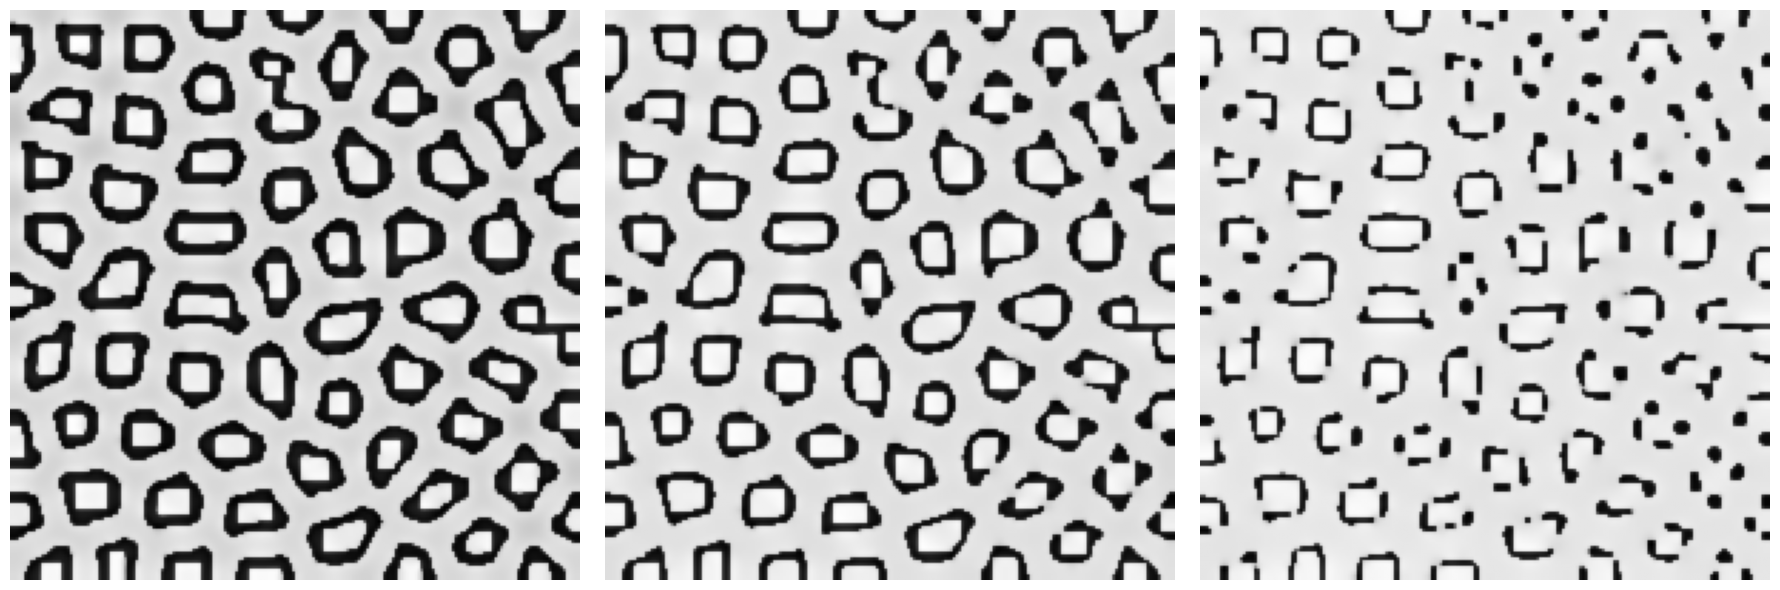

In [5]:
r2 = 7.0
#2000
for n in range(2000):
    U_new, V_new = calculate_new_values(U, V, dt, h, D, delta, alpha, beta, r2, r3)
    
    U[1:-1, 1:-1] = U_new
    V[1:-1, 1:-1] = V_new
    
    # Neumann boundary conditions
    U[0, :] = U[1, :]
    U[-1, :] = U[-2, :]
    U[:, 0] = U[:, 1]
    U[:, -1] = U[:, -2]

    V[0, :] = V[1, :]
    V[-1, :] = V[-2, :]
    V[:, 0] = V[:, 1]
    V[:, -1] = V[:, -2]

delta = 3.8
D = 0.15
steps = [10000, 15000, 22000]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
plot_idx = 0
current_step = 0

for target in steps:
    iterations = target - current_step
    
    for n in range(iterations):
        U_new, V_new = calculate_new_values(U, V, dt, h, D, delta, alpha, beta, r2, r3)
        
        U[1:-1, 1:-1] = U_new
        V[1:-1, 1:-1] = V_new
        
        # Neumann boundary conditions
        U[0, :] = U[1, :]
        U[-1, :] = U[-2, :]
        U[:, 0] = U[:, 1]
        U[:, -1] = U[:, -2]

        V[0, :] = V[1, :]
        V[-1, :] = V[-2, :]
        V[:, 0] = V[:, 1]
        V[:, -1] = V[:, -2]
        
    current_step = target
    
    
    axes[plot_idx].imshow(U, cmap='gray_r')
    axes[plot_idx].axis('off')
    plot_idx += 1

plt.tight_layout()
plt.show()
U_adult = U.copy()

**Artistic Visualization**

By interpreting the grid as an elevation map, a virtual light source is created. It casts shadows and, together with an artistic color palette, provides the flat two-dimensional image with an illusion of physical volume and depth.

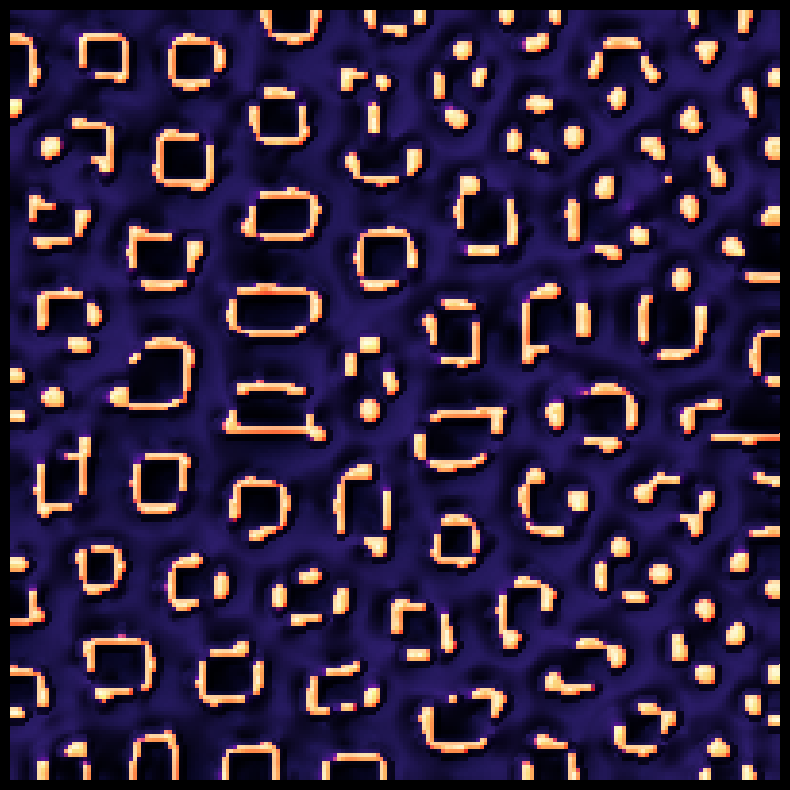

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
ls = LightSource(azdeg=315, altdeg=45)
color_palette = plt.cm.magma

rgb_image = ls.shade(U, cmap=color_palette, vert_exag=30.0, blend_mode='soft')

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(rgb_image)
ax.axis('off')
fig.patch.set_facecolor('black') 

plt.tight_layout()
plt.show()

**Stage 3: Hybrid Turing labyrinths**

In this visualization, the cubic interaction parameter $r_3$ is changed. In the original model, a high value ($r_3 = 3.5$) isolates the pigment into distinct spots. By lowering this threshold, instead of forming round spots, the activator waves merge into endless, intertwined labyrinths resembling fingerprints or the cerebral cortex.

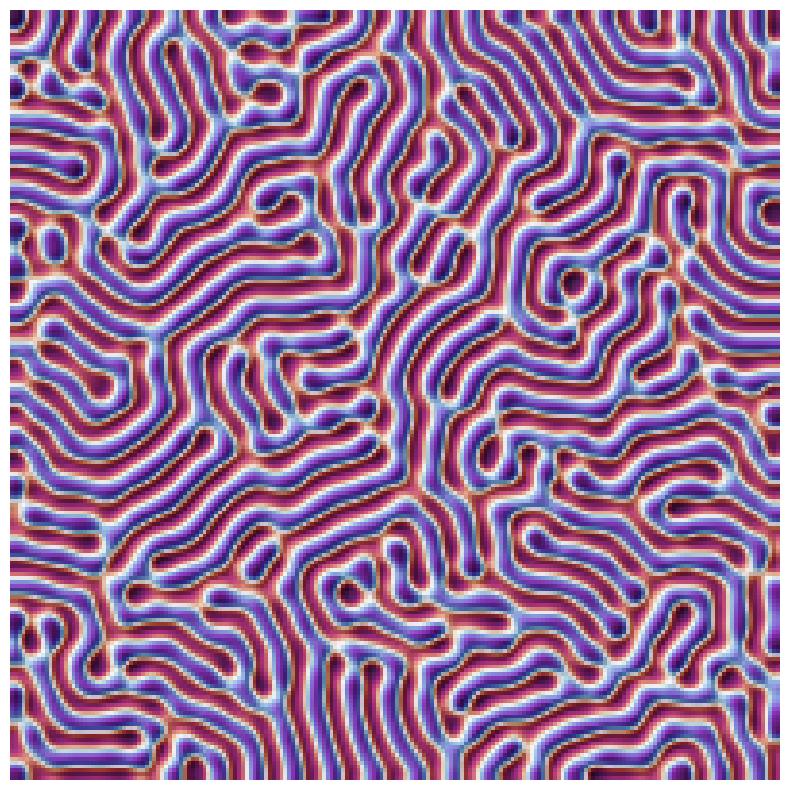

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource

U_lab = 0.1 * (np.random.rand(nx, ny) - 0.5)
V_lab = 0.1 * (np.random.rand(nx, ny) - 0.5)
D = 0.45
delta = 1.0
r2 = 0.0
r3 = 1.0  
for n in range(50000):
    U_new, V_new = calculate_new_values(U_lab, V_lab, dt, h, D, delta, alpha, beta, r2, r3)
    
    U_lab[1:-1, 1:-1] = U_new
    V_lab[1:-1, 1:-1] = V_new
    
    
    U_lab[0, :] = U_lab[1, :]
    U_lab[-1, :] = U_lab[-2, :]
    U_lab[:, 0] = U_lab[:, 1]
    U_lab[:, -1] = U_lab[:, -2]

    V_lab[0, :] = V_lab[1, :]
    V_lab[-1, :] = V_lab[-2, :]
    V_lab[:, 0] = V_lab[:, 1]
    V_lab[:, -1] = V_lab[:, -2]

ls = LightSource(azdeg=135, altdeg=45)
color_palette = plt.cm.twilight_shifted 

rgb_image = ls.shade(U_lab, cmap=color_palette, vert_exag=8.0, blend_mode='soft')

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(rgb_image)
ax.axis('off')

plt.tight_layout()
plt.show()

## 5. Validation 
The generated results of the mathematical model are compared with biological counterparts in nature, based on phylogenetic studies and observations.
- **First stage (Juvenile stage):** Selecting a high cubic suppression parameter ($r_3 = 3.5$) yields isolated spots. This accurately corresponds to the coat structure of a young leopard, where the primary pattern consists of small spots.
- **Second stage (Adult stage):** By modifying the parameters ($r_2$ is increased to $7.0$, $\delta$ is decreased to $3.8$, and $D$ to $0.15$) and allowing the system to evolve over different time steps, the dark spots grow, the activator concentration decreases in their centers, and they turn into rings and rosettes, which later gradually break apart. This dynamics perfectly replicates the coat structures of an adult leopard.

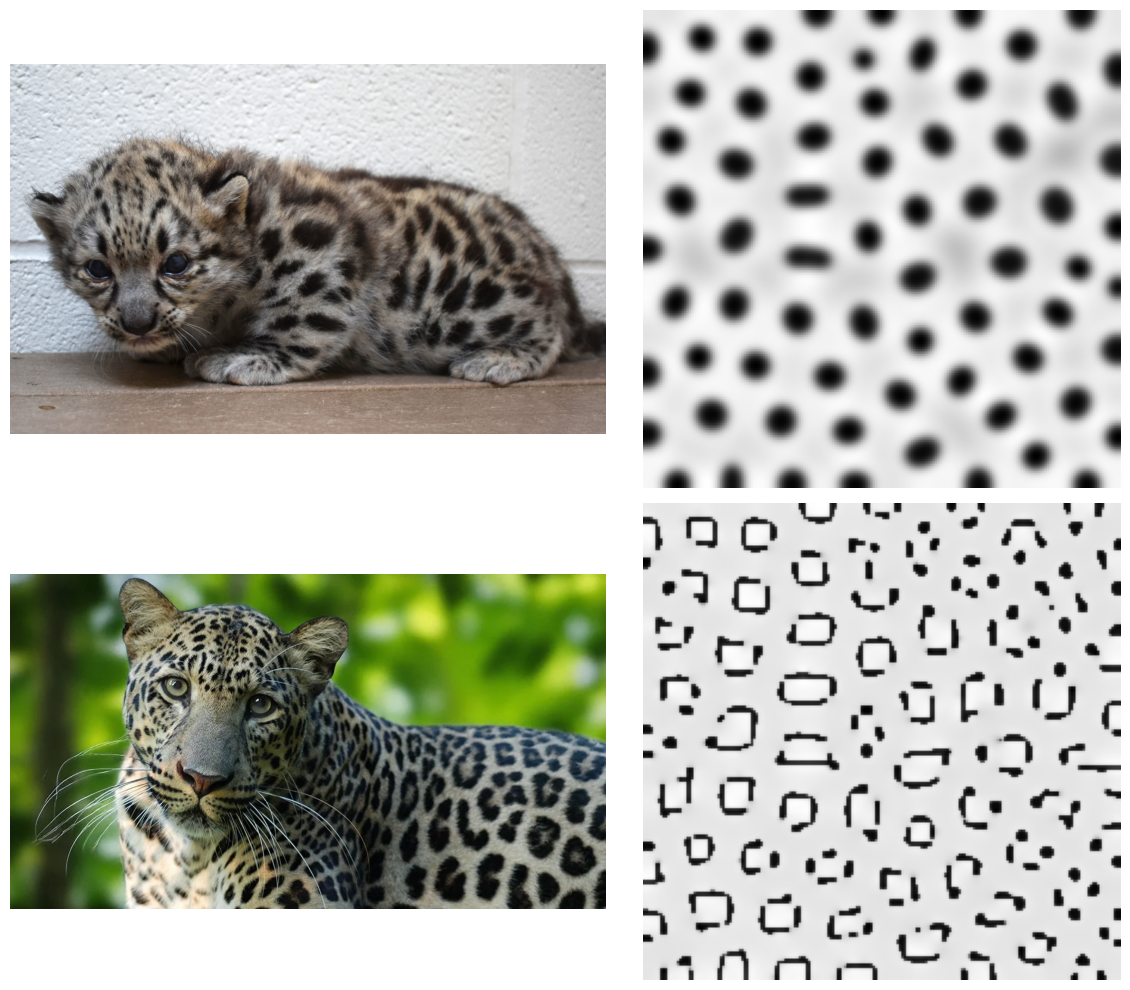

In [11]:
import matplotlib.pyplot as plt

juvenile_img = plt.imread('leopardas_jaunas.jpg')
adult_img = plt.imread('leopardas_suauges.jpg') 
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow(juvenile_img)
axes[0, 0].axis('off')

axes[0, 1].imshow(U_juvenile, cmap='gray_r')
axes[0, 1].axis('off')

axes[1, 0].imshow(adult_img)
axes[1, 0].axis('off')

axes[1, 1].imshow(U_adult, cmap='gray_r')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

### Conclusions
1. A morphogen Turing reaction-diffusion model has been successfully implemented, allowing for the digital simulation of biological tissue pigmentation processes.
2. It was determined that nonlinear coefficients directly control pattern morphology: by decreasing the $r_3$ parameter, the system transitions from isolated spots to a state of intertwined labyrinths or rosettes.
3. By applying Matplotlib 3D relief and light source parameters, mathematical matrices were successfully transformed into visual artworks.
4. Visual validation confirmed the hypothesis of Liu et al. (2006) – the model reflects the two-stage formation of animal skin patterns.

## References

[1] R. T. Liu, S. S. Liaw, and P. K. Maini, "Two-stage Turing model for generating pigment patterns on the leopard and the jaguar", *Physical Review E*, vol. 74, no. 1, p. 011914, 2006.